# EDA 02 (khảo sát): khoảng lấy mẫu và nhãn phương tiện

GPS ghi dày đến mức nào; tốc độ thật của từng phương tiện có nhãn. Notebook chỉ mô tả.

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 1 | GPS ghi dày đến mức nào? | Tham số thời gian của stay point |
| 2 | Tốc độ thật của từng phương tiện có nhãn? | Tham chiếu cho ngưỡng tốc độ (tuning/06) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`). Mục đánh số riêng trong từng notebook (bảng mục và notebook ở README).

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 03 mục 2. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

> **Giai đoạn: KHẢO SÁT (trước khi chia validation / test).** Chạy trên **toàn bộ 182 user**. Chỉ mô tả dữ liệu, **không chọn ngưỡng** ở đây. Ngưỡng chọn ở thư mục `notebooks/tuning/`, chỉ trên nhóm validation (D17).
>
> Các số trong ô văn bản bên dưới là của lần chạy cũ (bản chia 06/11); cập nhật sau khi chạy lại.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = None   # khảo sát: toàn bộ user (chỉ mô tả, không chọn ngưỡng)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=['speed'], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A
modes = R.modes
print(f"{len(users)} user, {len(files):,} file")

[20/182] đã đọc tới user 019 (3 giây)


[40/182] đã đọc tới user 039 (6 giây)


[60/182] đã đọc tới user 059 (8 giây)


[80/182] đã đọc tới user 079 (9 giây)


[100/182] đã đọc tới user 099 (11 giây)


[120/182] đã đọc tới user 119 (11 giây)


[140/182] đã đọc tới user 139 (13 giây)


[160/182] đã đọc tới user 159 (15 giây)


[180/182] đã đọc tới user 179 (17 giây)
[182/182] đã đọc tới user 181 (17 giây)


182 user, 18,670 file


## 1. Khoảng cách lấy mẫu

**Câu hỏi:** GPS ghi một điểm sau bao nhiêu giây? Phân phối có tách rõ giữa các chế độ ghi của thiết bị và khoảng trống không?

Biểu đồ dùng thang log cả hai trục. Cột cao rời rạc ở vài giây đầu là các chế độ ghi của thiết bị. Phần đuôi bên phải là khoảng trống. Các vạch xám là mốc thời gian để dễ đọc, không phải ngưỡng.


,dt_s
p50,2.0
p90,5.0
p95,5.0
p99,22.0
p99.9,3259.1
max,229604752.0


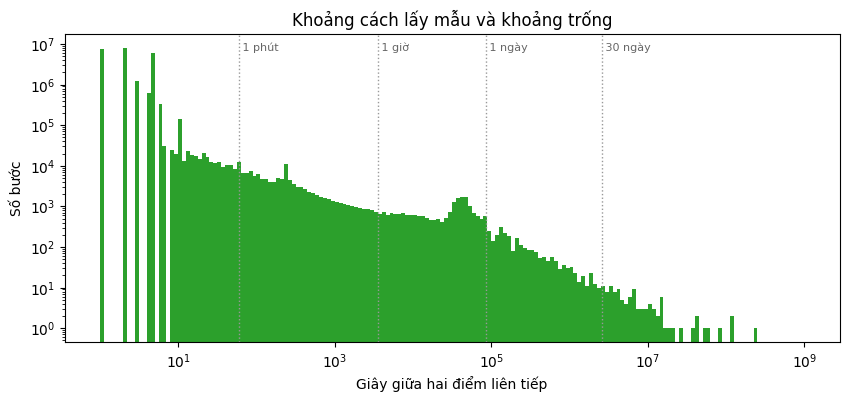

In [2]:
display(qtable(A["dt_q"], A["dt_max"], "dt_s"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(A["dt_hist"], DT_BINS, fill=True, color="#2ca02c")
ax.set_xscale("log"); ax.set_yscale("log")
for sec, label in ((60, "1 phút"), (3600, "1 giờ"), (86400, "1 ngày"), (30 * 86400, "30 ngày")):
    ax.axvline(sec, color="#999", ls=":", lw=1)
    ax.text(sec, ax.get_ylim()[1] * 0.4, f" {label}", fontsize=8, color="#666")
ax.set_xlabel("Giây giữa hai điểm liên tiếp")
ax.set_ylabel("Số bước")
ax.set_title("Khoảng cách lấy mẫu và khoảng trống")
plt.show()


Theo user: khoảng cách lấy mẫu điển hình (trung vị) và tỷ lệ bước đúng 1, 2, 5 giây.

In [3]:
display(users["median_dt_s"].round().value_counts().sort_index().rename("số user").to_frame().T)
users[["share_dt_1s", "share_dt_2s", "share_dt_5s"]].describe().round(3)

median_dt_s,1.0,2.0,3.0,4.0,5.0,12.0,16.0,17.0,18.0,19.0,20.0,21.0,24.0,25.0,28.0,50.0,53.0,54.0,60.0,62.0,63.0,72.0,74.0,75.0,76.0,78.0
số user,32,50,12,5,44,3,2,4,1,2,5,3,2,2,1,1,1,2,1,1,2,1,2,1,1,1


,share_dt_1s,share_dt_2s,share_dt_5s
count,182.000,182.000,182.000
mean,0.204,0.208,0.272
std,0.305,0.292,0.334
min,0.000,0.000,0.000
25%,0.000,0.009,0.010
50%,0.005,0.065,0.090
75%,0.381,0.246,0.409
max,0.997,0.995,0.982


## 2. Nhãn phương tiện (`labels.txt`)

**Câu hỏi:** với các đoạn đã có nhãn, tốc độ thật của từng phương tiện nằm ở đâu? Vùng tốc độ nào tách được phương tiện mặt đất (kể cả tàu) với máy bay? Mục này kiểm tra chéo vùng trũng thấy ở mục 1 (notebook 06).

Theo User Guide, thời gian trong `labels.txt` đã được đổi sang GMT. Kiểm tra: nếu tốc độ đi bộ (`walk`) có trung vị khoảng 3–6 km/h thì nhãn khớp với quỹ đạo; nếu lệch hẳn, nhãn đang lệch giờ.

Tốc độ tính trên mọi bước nằm trong khoảng thời gian của nhãn. Phân vị tính xấp xỉ từ histogram.


In [4]:
names = [str(x) for x in A["mode_names"]]
H = A["mode_hist"]
mt = modes.set_index("mode").loc[names].copy()
for q in (0.5, 0.95, 0.99, 0.999):
    mt[f"p{q * 100:g}_km_h"] = [hist_quantile(H[i], SPEED_BINS, q) for i in range(len(names))]
mt.sort_values("hours", ascending=False).round(2)


,n_labels,hours,n_steps,p50_km_h,p95_km_h,p99_km_h,p99.9_km_h
mode,,,,,,,
walk,6460,5460.50,1318057,4.22,14.96,42.17,133.35
bike,2089,2410.27,776122,11.89,23.71,42.17,105.93
car,993,1725.14,497492,29.85,94.41,118.85,211.35
bus,2853,1507.05,1183654,16.79,59.57,94.41,118.85
train,299,745.44,559058,94.41,167.88,211.35,237.14
taxi,1179,659.09,203973,33.50,74.99,105.93,118.85
subway,813,396.33,273130,47.32,74.99,94.41,167.88
airplane,17,40.80,8993,668.34,841.40,944.06,944.06
boat,7,4.65,3551,3.76,74.99,74.99,149.62


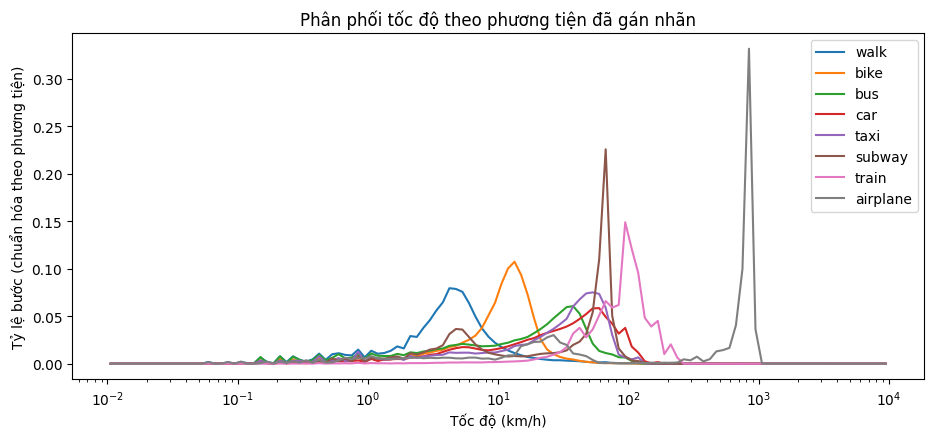

In [5]:
show = [m for m in ["walk", "bike", "bus", "car", "taxi", "subway", "train", "airplane"] if m in names]
centers = np.sqrt(SPEED_BINS[:-1] * SPEED_BINS[1:])
fig, ax = plt.subplots(figsize=(11, 4.5))
for m in show:
    h = H[names.index(m)]
    if h.sum() > 0:
        ax.plot(centers, h / h.sum(), label=m)
ax.set_xscale("log")
ax.set_xlabel("Tốc độ (km/h)")
ax.set_ylabel("Tỷ lệ bước (chuẩn hóa theo phương tiện)")
ax.set_title("Phân phối tốc độ theo phương tiện đã gán nhãn")
ax.legend()
plt.show()
